In [23]:
import os
os.chdir("/home/jupyter/fire-impact-curves/notebooks")
print(os.getcwd())

import sys
sys.path.append("/home/jupyter/fire-impact-curves")
import ee
ee.Authenticate()
ee.Initialize(project="tree-fire-510209")

from src.fires import load_fire
from src.grids import pad_bounds


/home/jupyter/fire-impact-curves/notebooks


Enter verification code:  4/1AUn6Hd_0JkmYjtXVHD3HraAHL3h96SFyC89VAfooYkgYJOVSjE7GMbNidIY



Successfully saved authorization token.


In [7]:
import ee

def get_agb_with_sd(year):
    coll = ee.ImageCollection("ESA/CCI/Above_Ground_Biomass/V6_0").filterDate(f"{year}-01-01", f"{year}-12-31")
    n = coll.size().getInfo()
    if n == 0:
        raise RuntimeError(f"no CCI AGB image for {year}")
    return coll.first().select(["agb", "agb_sd"])

uid = "2020_112"
fire = load_fire(uid)
aoi = ee.Geometry.Rectangle(list(pad_bounds(fire.total_bounds, 0.15)))
image = get_agb_with_sd(2019)

task = ee.batch.Export.image.toCloudStorage(
    image=image, description=f"agb_sd_pilot_{uid}",
    bucket="tree-fire-510209-data",
    fileNamePrefix=f"fire-impact-curves/data/agb_sd_pilot/agb_sd_{uid}",
    region=aoi, scale=100, maxPixels=1e9,
)
task.start()
print("submitted, checking status...")

import time
while task.active():
    time.sleep(20)
print("final state:", task.status()["state"])

if task.status()["state"] == "COMPLETED":
    import subprocess, os
    os.makedirs("../data/agb_sd_pilot", exist_ok=True)
    out_path = f"../data/agb_sd_pilot/agb_sd_{uid}.tif"
    subprocess.run(["gsutil", "cp",
                     f"gs://tree-fire-510209-data/fire-impact-curves/data/agb_sd_pilot/agb_sd_{uid}.tif",
                     out_path], check=True)
    print("downloaded ->", out_path)
else:
    print(task.status())

submitted, checking status...
final state: COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_sd_pilot/agb_sd_2020_112.tif...
/ [1 files][  1.3 MiB/  1.3 MiB]                                                
Operation completed over 1 objects/1.3 MiB.                                      


downloaded -> ../data/agb_sd_pilot/agb_sd_2020_112.tif


In [8]:
import rasterio
import numpy as np

with rasterio.open("../data/agb_sd_pilot/agb_sd_2020_112.tif") as src:
    agb = src.read(1).astype(float)
    agb_sd = src.read(2).astype(float)
    nodata = src.nodata
    print("nodata value:", nodata)

valid = np.isfinite(agb) & np.isfinite(agb_sd) & (agb > 0)
if nodata is not None:
    valid &= (agb != nodata) & (agb_sd != nodata)

print("valid pixels:", valid.sum(), "of", agb.size)
print(f"AGB: mean={agb[valid].mean():.1f}, median={np.median(agb[valid]):.1f}")
print(f"AGB_SD: mean={agb_sd[valid].mean():.1f}, median={np.median(agb_sd[valid]):.1f}")

relative_uncertainty = agb_sd[valid] / agb[valid]
print(f"relative uncertainty (SD/AGB): mean={relative_uncertainty.mean():.2f}, "
      f"median={np.median(relative_uncertainty):.2f}, "
      f"90th pct={np.percentile(relative_uncertainty, 90):.2f}")

nodata value: None
valid pixels: 584416 of 692664
AGB: mean=79.4, median=65.0
AGB_SD: mean=49.1, median=40.0
relative uncertainty (SD/AGB): mean=0.62, median=0.62, 90th pct=0.71


In [9]:
import ee, subprocess, os, time

def export_and_download_agb(uid, year, aoi):
    coll = ee.ImageCollection("ESA/CCI/Above_Ground_Biomass/V6_0").filterDate(f"{year}-01-01", f"{year}-12-31")
    image = coll.first().select("agb")
    task = ee.batch.Export.image.toCloudStorage(
        image=image, description=f"agb_stability_{uid}_{year}",
        bucket="tree-fire-510209-data",
        fileNamePrefix=f"fire-impact-curves/data/agb_stability/agb_{uid}_{year}",
        region=aoi, scale=100, maxPixels=1e9,
    )
    task.start()
    while task.active():
        time.sleep(20)
    print(uid, year, "->", task.status()["state"])
    if task.status()["state"] == "COMPLETED":
        os.makedirs("../data/agb_stability", exist_ok=True)
        out_path = f"../data/agb_stability/agb_{uid}_{year}.tif"
        subprocess.run(["gsutil", "cp",
                         f"gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_{uid}_{year}.tif",
                         out_path], check=True)
        return out_path
    return None

uid = "2020_112"
fire = load_fire(uid)
aoi = ee.Geometry.Rectangle(list(pad_bounds(fire.total_bounds, 0.15)))

paths = {}
for year in [2015, 2017, 2018]:
    paths[year] = export_and_download_agb(uid, year, aoi)
print(paths)

2020_112 2015 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_112_2015.tif...
/ [1 files][771.9 KiB/771.9 KiB]                                                
Operation completed over 1 objects/771.9 KiB.                                    


2020_112 2017 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_112_2017.tif...
/ [1 files][761.7 KiB/761.7 KiB]                                                
Operation completed over 1 objects/761.7 KiB.                                    


2020_112 2018 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_112_2018.tif...
/ [1 files][760.3 KiB/760.3 KiB]                                                
Operation completed over 1 objects/760.3 KiB.                                    


{2015: '../data/agb_stability/agb_2020_112_2015.tif', 2017: '../data/agb_stability/agb_2020_112_2017.tif', 2018: '../data/agb_stability/agb_2020_112_2018.tif'}


In [10]:
import rasterio
import numpy as np

paths_all = {
    2015: paths[2015], 2017: paths[2017], 2018: paths[2018],
    2019: "../data/cci_agb_ee/agb_2020_112_2019.tif",
}

arrays = {}
for yr, p in paths_all.items():
    with rasterio.open(p) as src:
        arrays[yr] = src.read(1).astype(float)

shapes = {yr: arr.shape for yr, arr in arrays.items()}
print("shapes:", shapes)
assert len(set(shapes.values())) == 1, "shapes don't match, need to align grids before continuing"

years = sorted(arrays.keys())
stack = np.stack([arrays[yr] for yr in years], axis=0)
valid = np.all(np.isfinite(stack) & (stack > 0), axis=0)

mean_agb = stack.mean(axis=0)
std_agb = stack.std(axis=0)
cv = std_agb / mean_agb

print("valid pixels:", valid.sum())
print(f"year-to-year CV across pre-fire years (2015,2017,2018,2019): "
      f"mean={cv[valid].mean():.2f}, median={np.median(cv[valid]):.2f}, "
      f"90th={np.percentile(cv[valid],90):.2f}, max={cv[valid].max():.2f}")

unstable = cv[valid] > 0.3
print(f"fraction of pixels with >30% relative swing across pre-fire years: {unstable.mean():.3f}")

shapes: {2015: (744, 931), 2017: (744, 931), 2018: (744, 931), 2019: (744, 931)}
valid pixels: 571885
year-to-year CV across pre-fire years (2015,2017,2018,2019): mean=0.28, median=0.25, 90th=0.48, max=1.65
fraction of pixels with >30% relative swing across pre-fire years: 0.379


/var/tmp/ipykernel_6065/4002686815.py:24: RuntimeWarning: invalid value encountered in divide
  cv = std_agb / mean_agb


In [11]:
uid2 = "2020_841874"
fire2 = load_fire(uid2)
aoi2 = ee.Geometry.Rectangle(list(pad_bounds(fire2.total_bounds, 0.15)))

paths2 = {}
for year in [2015, 2017, 2018]:
    paths2[year] = export_and_download_agb(uid2, year, aoi2)
print(paths2)

2020_841874 2015 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_841874_2015.tif...
/ [1 files][383.7 KiB/383.7 KiB]                                                
Operation completed over 1 objects/383.7 KiB.                                    


2020_841874 2017 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_841874_2017.tif...
/ [1 files][382.2 KiB/382.2 KiB]                                                
Operation completed over 1 objects/382.2 KiB.                                    


2020_841874 2018 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_841874_2018.tif...
/ [1 files][380.6 KiB/380.6 KiB]                                                
Operation completed over 1 objects/380.6 KiB.                                    


{2015: '../data/agb_stability/agb_2020_841874_2015.tif', 2017: '../data/agb_stability/agb_2020_841874_2017.tif', 2018: '../data/agb_stability/agb_2020_841874_2018.tif'}


In [12]:
paths_all2 = {
    2015: paths2[2015], 2017: paths2[2017], 2018: paths2[2018],
    2019: "../data/cci_agb_ee/agb_2020_841874_2019.tif",
}

arrays2 = {}
for yr, p in paths_all2.items():
    with rasterio.open(p) as src:
        arrays2[yr] = src.read(1).astype(float)

shapes2 = {yr: arr.shape for yr, arr in arrays2.items()}
print("shapes:", shapes2)
assert len(set(shapes2.values())) == 1, "shapes don't match"

years2 = sorted(arrays2.keys())
stack2 = np.stack([arrays2[yr] for yr in years2], axis=0)
valid2 = np.all(np.isfinite(stack2) & (stack2 > 0), axis=0)

mean_agb2 = stack2.mean(axis=0)
std_agb2 = stack2.std(axis=0)
with np.errstate(invalid="ignore", divide="ignore"):
    cv2 = std_agb2 / mean_agb2

print("valid pixels:", valid2.sum())
print(f"year-to-year CV ({uid2}): mean={cv2[valid2].mean():.2f}, median={np.median(cv2[valid2]):.2f}, "
      f"90th={np.percentile(cv2[valid2],90):.2f}, max={cv2[valid2].max():.2f}")
print(f"fraction with >30% swing: {(cv2[valid2] > 0.3).mean():.3f}")

shapes: {2015: (497, 539), 2017: (497, 539), 2018: (497, 539), 2019: (497, 539)}
valid pixels: 255656
year-to-year CV (2020_841874): mean=0.24, median=0.20, 90th=0.46, max=1.63
fraction with >30% swing: 0.275


In [13]:
import pandas as pd
full = pd.read_parquet("../data/processed/all_cells_current.parquet")

import sys
sys.path.append("/home/jupyter/fire-impact-curves")
from src.curves import leave_one_fire_out_cv, fit_group

grp = full[(full["height_class"] == "10-20m") & (full["forest_type_label"] == "evergreen_needleleaf")]
test_fires = grp["uid"].unique()[:8]
print(f"testing on {len(test_fires)} fires:", list(test_fires))

testing on 8 fires: ['2020_112', '2020_135', '2020_464', '2021_190', '2020_838262', '2021_13058', '2021_12957', '2021_12806']


In [14]:
test_fires = ['2020_112', '2020_135', '2020_464', '2021_190', '2020_838262', '2021_13058', '2021_12957', '2021_12806']

fire_before_year = {uid: int(uid[:4]) - 1 for uid in test_fires}
print(fire_before_year)

stability_paths = {}
for uid in test_fires:
    fire_i = load_fire(uid)
    aoi_i = ee.Geometry.Rectangle(list(pad_bounds(fire_i.total_bounds, 0.15)))
    stability_paths[uid] = {}
    for year in [2015, 2017, 2018]:
        stability_paths[uid][year] = export_and_download_agb(uid, year, aoi_i)
    # the "before" year is already cached from the main pipeline
    stability_paths[uid][fire_before_year[uid]] = f"../data/cci_agb_ee/agb_{uid}_{fire_before_year[uid]}.tif"

print(stability_paths)

{'2020_112': 2019, '2020_135': 2019, '2020_464': 2019, '2021_190': 2020, '2020_838262': 2019, '2021_13058': 2020, '2021_12957': 2020, '2021_12806': 2020}
2020_112 2015 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_112_2015.tif...
/ [1 files][771.9 KiB/771.9 KiB]                                                
Operation completed over 1 objects/771.9 KiB.                                    


2020_112 2017 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_112_2017.tif...
/ [1 files][761.7 KiB/761.7 KiB]                                                
Operation completed over 1 objects/761.7 KiB.                                    


2020_112 2018 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_112_2018.tif...
/ [1 files][760.3 KiB/760.3 KiB]                                                
Operation completed over 1 objects/760.3 KiB.                                    


... (39 outputs left out)

Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2021_12806_2017.tif...
/ [1 files][229.0 KiB/229.0 KiB]                                                
Operation completed over 1 objects/229.0 KiB.                                    


2021_12806 2018 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2021_12806_2018.tif...
/ [1 files][229.4 KiB/229.4 KiB]                                                
Operation completed over 1 objects/229.4 KiB.                                    


{'2020_112': {2015: '../data/agb_stability/agb_2020_112_2015.tif', 2017: '../data/agb_stability/agb_2020_112_2017.tif', 2018: '../data/agb_stability/agb_2020_112_2018.tif', 2019: '../data/cci_agb_ee/agb_2020_112_2019.tif'}, '2020_135': {2015: '../data/agb_stability/agb_2020_135_2015.tif', 2017: '../data/agb_stability/agb_2020_135_2017.tif', 2018: '../data/agb_stability/agb_2020_135_2018.tif', 2019: '../data/cci_agb_ee/agb_2020_135_2019.tif'}, '2020_464': {2015: '../data/agb_stability/agb_2020_464_2015.tif', 2017: '../data/agb_stability/agb_2020_464_2017.tif', 2018: '../data/agb_stability/agb_2020_464_2018.tif', 2019: '../data/cci_agb_ee/agb_2020_464_2019.tif'}, '2021_190': {2015: '../data/agb_stability/agb_2021_190_2015.tif', 2017: '../data/agb_stability/agb_2021_190_2017.tif', 2018: '../data/agb_stability/agb_2021_190_2018.tif', 2020: '../data/cci_agb_ee/agb_2021_190_2020.tif'}, '2020_838262': {2015: '../data/agb_stability/agb_2020_838262_2015.tif', 2017: '../data/agb_stability/agb_20

In [16]:
import numpy as np
from rasterio.features import rasterize
from src.grids import read_window, reproject_to_grid, pad_bounds
from src.fires import inner_burn_area, utm_epsg_for
from src.pipeline import DNBR_DROP_BELOW

def stability_cv_for_fire(uid, year_paths, agb_after_years, min_agb_before=10):
    fire = load_fire(uid)
    bounds = pad_bounds(fire.total_bounds, 0.15)
    lon, lat = fire.geometry.iloc[0].centroid.x, fire.geometry.iloc[0].centroid.y
    utm_epsg = utm_epsg_for(lon, lat)
    inner = inner_burn_area(fire, utm_epsg=utm_epsg)

    years = sorted(year_paths.keys())
    before_year = years[-1]
    arrays, tr_ref, crs_ref, shape = {}, None, None, None
    for yr in years:
        arr, tr, crs = read_window(year_paths[yr], bounds)
        arrays[yr] = arr
        if tr_ref is None:
            tr_ref, crs_ref, shape = tr, crs, arr.shape

    mask_inner = rasterize(
        [(g, 1) for g in inner.geometry], out_shape=shape,
        transform=tr_ref, fill=0, dtype="uint8",
    ).astype(bool)

    # match build_cell_table's exact validity rule: before-year valid AND above
    # threshold, AND every after-year valid too
    valid = np.isfinite(arrays[before_year]) & (arrays[before_year] > min_agb_before)
    for yr in agb_after_years:
        after_arr, _, _ = read_window(f"../data/cci_agb_ee/agb_{uid}_{yr}.tif", bounds)
        valid &= np.isfinite(after_arr)
    keep = mask_inner & valid

    stack = np.stack([arrays[yr] for yr in years], axis=0)
    mean_agb = stack.mean(axis=0)
    std_agb = stack.std(axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        cv = std_agb / mean_agb

    severity_path = f"../data/severity/severity_{uid}.tif"
    dnbr_arr, tr_d, crs_d = read_window(severity_path, bounds, band=1)
    dnbr_100m = reproject_to_grid(
        np.nan_to_num(dnbr_arr, nan=-9999).astype("float32"), tr_d, crs_d, shape, tr_ref, crs_ref,
        src_nodata=-9999,
    )

    d = pd.DataFrame({"uid": uid, "cv": cv[keep], "dnbr_recomputed": dnbr_100m[keep]})
    d = d[d["dnbr_recomputed"] >= DNBR_DROP_BELOW].copy()
    return d

fire_after_years = {
    "2020_112": [2021, 2022], "2020_135": [2021, 2022], "2020_464": [2021, 2022],
    "2020_838262": [2021, 2022], "2021_190": [2022], "2021_13058": [2022],
    "2021_12957": [2022], "2021_12806": [2022],
}

cv_results = []
for uid, yp in stability_paths.items():
    cv_results.append(stability_cv_for_fire(uid, yp, fire_after_years[uid]))
cv_full = pd.concat(cv_results, ignore_index=True)

for uid in stability_paths:
    recomputed = cv_full[cv_full["uid"] == uid]["dnbr_recomputed"].reset_index(drop=True)
    existing = full[full["uid"] == uid]["dnbr"].reset_index(drop=True)
    if len(recomputed) != len(existing):
        print(f"{uid}: MISMATCH row count ({len(recomputed)} vs {len(existing)})")
    else:
        print(f"{uid}: {len(existing)} cells, max dnbr diff = {(recomputed - existing).abs().max():.6f}")

/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return

2020_112: 120632 cells, max dnbr diff = 0.000000
2020_135: 109019 cells, max dnbr diff = 0.000000
2020_464: 62 cells, max dnbr diff = 0.000000
2021_190: 50016 cells, max dnbr diff = 0.000000
2020_838262: 1473 cells, max dnbr diff = 0.000000
2021_13058: 2536 cells, max dnbr diff = 0.000000
2021_12957: 13167 cells, max dnbr diff = 0.000000
2021_12806: 1112 cells, max dnbr diff = 0.000000


In [18]:
from src.curves import fit_group, logistic

merged_parts = []
for uid in stability_paths:
    sub_full = full[full["uid"] == uid].reset_index(drop=True)
    sub_cv = cv_full[cv_full["uid"] == uid].reset_index(drop=True)
    assert len(sub_full) == len(sub_cv), f"{uid}: length mismatch {len(sub_full)} vs {len(sub_cv)}"
    merged = sub_full.copy()
    merged["cv"] = sub_cv["cv"].values
    merged_parts.append(merged)
merged_full = pd.concat(merged_parts, ignore_index=True)

grp = full[(full["height_class"] == "10-20m") & (full["forest_type_label"] == "evergreen_needleleaf")]
grp_with_cv = merged_full[(merged_full["height_class"] == "10-20m") & (merged_full["forest_type_label"] == "evergreen_needleleaf")]

threshold = 0.3
rows = []
for uid in stability_paths:
    train = grp[grp["uid"] != uid]
    fit = fit_group(train, min_fires=3, min_cells=200)
    if fit["status"] not in ("fitted", "degenerate_fit"):
        continue
    held = grp_with_cv[grp_with_cv["uid"] == uid]
    for sev, sev_grp in held.groupby("severity", observed=True):
        if len(sev_grp) == 0:
            continue
        x = sev_grp["dnbr"].mean()
        predicted = logistic(x, fit["l_max"], fit["k"], fit["x0"])
        actual_unfiltered = sev_grp["loss2022"].mean()
        filtered = sev_grp[sev_grp["cv"] <= threshold]
        actual_filtered = filtered["loss2022"].mean() if len(filtered) > 0 else np.nan
        rows.append({
            "uid": uid, "severity": sev, "n_cells": len(sev_grp), "n_kept": len(filtered),
            "predicted": predicted,
            "residual_unfiltered": actual_unfiltered - predicted,
            "residual_filtered": (actual_filtered - predicted) if pd.notna(actual_filtered) else np.nan,
        })

result = pd.DataFrame(rows)
print(result.to_string(index=False))
print()
print(f"MAE unfiltered: {result['residual_unfiltered'].abs().mean():.3f}")
print(f"MAE filtered:   {result['residual_filtered'].abs().mean():.3f}")

        uid severity  n_cells  n_kept  predicted  residual_unfiltered  residual_filtered
   2020_112     mild     4883    2726   0.001050            -0.559979          -0.479961
   2020_112 moderate    16435    8872   0.059335            -0.080568          -0.040869
   2020_112   severe     4953    2833   0.160249             0.079930           0.126304
   2020_135     mild     2134    1365   0.000161            -0.339686          -0.223331
   2020_135 moderate    14560    8583   0.084689            -0.029512           0.073665
   2020_135   severe    12768    8158   0.155695             0.031857           0.095576
   2020_464 moderate       17      15   0.147616             0.382263           0.357343
   2020_464   severe       15      13   0.166384             0.500466           0.493563
   2021_190     mild     4679    2290   0.000133            -0.056607           0.083925
   2021_190 moderate    11268    5761   0.024234             0.108752           0.267516
   2021_190   severe 

In [19]:
already_done = set(stability_paths.keys())
more_fires = [uid for uid in grp["uid"].unique() if uid not in already_done][:12]
print(f"{len(more_fires)} additional fires selected:", more_fires)

12 additional fires selected: ['2021_26579', '2021_26587', '2021_26580', '2021_26577', '2021_17228', '2021_18246', '2021_18206', '2020_6787', '2020_6783', '2021_53', '2020_6785', '2020_6781']


In [20]:
more_fires = ['2021_26579', '2021_26587', '2021_26580', '2021_26577', '2021_17228',
              '2021_18246', '2021_18206', '2020_6787', '2020_6783', '2021_53',
              '2020_6785', '2020_6781']

more_before_year = {uid: int(uid[:4]) - 1 for uid in more_fires}
more_after_years = {uid: ([2021, 2022] if uid.startswith("2020") else [2022]) for uid in more_fires}

for uid in more_fires:
    fire_i = load_fire(uid)
    aoi_i = ee.Geometry.Rectangle(list(pad_bounds(fire_i.total_bounds, 0.15)))
    stability_paths[uid] = {}
    for year in [2015, 2017, 2018]:
        stability_paths[uid][year] = export_and_download_agb(uid, year, aoi_i)
    stability_paths[uid][more_before_year[uid]] = f"../data/cci_agb_ee/agb_{uid}_{more_before_year[uid]}.tif"
    fire_after_years[uid] = more_after_years[uid]

print(f"{len(stability_paths)} fires total now have stability data")

/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2021_26579 2015 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2021_26579_2015.tif...
/ [1 files][381.6 KiB/381.6 KiB]                                                
Operation completed over 1 objects/381.6 KiB.                                    


2021_26579 2017 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2021_26579_2017.tif...
/ [1 files][387.0 KiB/387.0 KiB]                                                
Operation completed over 1 objects/387.0 KiB.                                    


2021_26579 2018 -> COMPLETED


... (64 outputs left out)

Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_6781_2017.tif...
/ [1 files][820.9 KiB/820.9 KiB]                                                
Operation completed over 1 objects/820.9 KiB.                                    


2020_6781 2018 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_6781_2018.tif...
/ [1 files][802.5 KiB/802.5 KiB]                                                
Operation completed over 1 objects/802.5 KiB.                                    


20 fires total now have stability data


In [24]:
grp_eb = full[(full["height_class"] == "10-20m") & (full["forest_type_label"] == "evergreen_broadleaf")]
eb_fires = list(grp_eb["uid"].unique()[:15])
print(f"{len(eb_fires)} Evergreen Broadleaf fires selected:", eb_fires)


15 Evergreen Broadleaf fires selected: ['2020_841874', '2020_838262', '2020_818141', '2021_750951', '2020_66789', '2020_901450', '2021_5641', '2020_4470', '2020_9413', '2020_4074', '2020_10820', '2020_10559', '2020_8602', '2020_14027', '2020_4157']


In [25]:
eb_before_year = {uid: int(uid[:4]) - 1 for uid in eb_fires}
eb_after_years = {uid: ([2021, 2022] if uid.startswith("2020") else [2022]) for uid in eb_fires}

eb_stability_paths = {}
for uid in eb_fires:
    fire_i = load_fire(uid)
    aoi_i = ee.Geometry.Rectangle(list(pad_bounds(fire_i.total_bounds, 0.15)))
    eb_stability_paths[uid] = {}
    for year in [2015, 2017, 2018]:
        eb_stability_paths[uid][year] = export_and_download_agb(uid, year, aoi_i)
    eb_stability_paths[uid][eb_before_year[uid]] = f"../data/cci_agb_ee/agb_{uid}_{eb_before_year[uid]}.tif"

print(f"{len(eb_stability_paths)} Evergreen Broadleaf fires pulled")


2020_841874 2015 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_841874_2015.tif...
/ [1 files][383.7 KiB/383.7 KiB]                                                
Operation completed over 1 objects/383.7 KiB.                                    


2020_841874 2017 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_841874_2017.tif...
/ [1 files][382.2 KiB/382.2 KiB]                                                
Operation completed over 1 objects/382.2 KiB.                                    


2020_841874 2018 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_841874_2018.tif...
/ [1 files][380.6 KiB/380.6 KiB]                                                
Operation completed over 1 objects/380.6 KiB.                                    


... (81 outputs left out)

Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_4157_2017.tif...
/ [1 files][238.7 KiB/238.7 KiB]                                                
Operation completed over 1 objects/238.7 KiB.                                    


2020_4157 2018 -> COMPLETED


Copying gs://tree-fire-510209-data/fire-impact-curves/data/agb_stability/agb_2020_4157_2018.tif...
/ [1 files][237.2 KiB/237.2 KiB]                                                
Operation completed over 1 objects/237.2 KiB.                                    


15 Evergreen Broadleaf fires pulled


In [26]:
eb_cv_results = []
for uid, yp in eb_stability_paths.items():
    eb_cv_results.append(stability_cv_for_fire(uid, yp, eb_after_years[uid]))
eb_cv_full = pd.concat(eb_cv_results, ignore_index=True)

for uid in eb_stability_paths:
    recomputed = eb_cv_full[eb_cv_full["uid"] == uid]["dnbr_recomputed"].reset_index(drop=True)
    existing = full[full["uid"] == uid]["dnbr"].reset_index(drop=True)
    if len(recomputed) != len(existing):
        print(f"{uid}: MISMATCH row count ({len(recomputed)} vs {len(existing)})")
    else:
        print(f"{uid}: {len(existing)} cells, max dnbr diff = {(recomputed - existing).abs().max():.6f}")


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(
/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: RuntimeWarning: ../data/fire_atlas/SHP_perimeters/GFA_v20240409_perimeters_2021.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


2020_841874: 462 cells, max dnbr diff = 0.000000
2020_838262: 1473 cells, max dnbr diff = 0.000000
2020_818141: 382 cells, max dnbr diff = 0.000000
2021_750951: 61 cells, max dnbr diff = 0.000000
2020_66789: 2250 cells, max dnbr diff = 0.000000
2020_901450: 16142 cells, max dnbr diff = 0.000000
2021_5641: 4 cells, max dnbr diff = 0.000000
2020_4470: 22 cells, max dnbr diff = 0.000000
2020_9413: 26 cells, max dnbr diff = 0.000000
2020_4074: 323 cells, max dnbr diff = 0.000000
2020_10820: 82 cells, max dnbr diff = 0.000000
2020_10559: 647 cells, max dnbr diff = 0.000000
2020_8602: 539 cells, max dnbr diff = 0.000000
2020_14027: 192 cells, max dnbr diff = 0.000000
2020_4157: 109 cells, max dnbr diff = 0.000000


In [27]:
eb_merged_parts = []
for uid in eb_stability_paths:
    sub_full = full[full["uid"] == uid].reset_index(drop=True)
    sub_cv = eb_cv_full[eb_cv_full["uid"] == uid].reset_index(drop=True)
    assert len(sub_full) == len(sub_cv), f"{uid}: length mismatch {len(sub_full)} vs {len(sub_cv)}"
    merged = sub_full.copy()
    merged["cv"] = sub_cv["cv"].values
    eb_merged_parts.append(merged)
eb_merged_full = pd.concat(eb_merged_parts, ignore_index=True)

grp_eb = full[(full["height_class"] == "10-20m") & (full["forest_type_label"] == "evergreen_broadleaf")]
grp_eb_with_cv = eb_merged_full[(eb_merged_full["height_class"] == "10-20m") & (eb_merged_full["forest_type_label"] == "evergreen_broadleaf")]

threshold = 0.3
rows = []
for uid in eb_stability_paths:
    train = grp_eb[grp_eb["uid"] != uid]
    fit = fit_group(train, min_fires=3, min_cells=200)
    if fit["status"] not in ("fitted", "degenerate_fit"):
        continue
    held = grp_eb_with_cv[grp_eb_with_cv["uid"] == uid]
    for sev, sev_grp in held.groupby("severity", observed=True):
        if len(sev_grp) == 0:
            continue
        x = sev_grp["dnbr"].mean()
        predicted = logistic(x, fit["l_max"], fit["k"], fit["x0"])
        actual_unweighted = sev_grp["loss2022"].mean()
        weights = 1 / (1 + sev_grp["cv"].clip(lower=0))
        actual_weighted = np.average(sev_grp["loss2022"], weights=weights)
        filtered = sev_grp[sev_grp["cv"] <= threshold]
        actual_filtered = filtered["loss2022"].mean() if len(filtered) > 0 else np.nan
        rows.append({
            "uid": uid, "severity": sev, "n_cells": len(sev_grp), "n_kept": len(filtered),
            "predicted": predicted,
            "residual_unweighted": actual_unweighted - predicted,
            "residual_weighted": actual_weighted - predicted,
            "residual_filtered": (actual_filtered - predicted) if pd.notna(actual_filtered) else np.nan,
        })

result_eb = pd.DataFrame(rows)
print(result_eb.to_string(index=False))
print()
print(f"MAE unweighted: {result_eb['residual_unweighted'].abs().mean():.3f}")
print(f"MAE weighted:   {result_eb['residual_weighted'].abs().mean():.3f}")
print(f"MAE filtered:   {result_eb['residual_filtered'].abs().mean():.3f}")


        uid severity  n_cells  n_kept  predicted  residual_unweighted  residual_weighted  residual_filtered
2020_841874     mild      200     182   0.032465             0.082518           0.084800           0.098575
2020_841874 moderate      112      99   0.095999             0.191072           0.194073           0.187219
2020_841874   severe        1       1   0.225186             0.024814           0.024814           0.024814
2020_838262     mild      839     603   0.028664            -0.047078          -0.041367          -0.019186
2020_838262 moderate       19      13   0.078250             0.098514           0.100185           0.150605
2020_818141     mild      212     203   0.030222             0.308705           0.308230           0.311864
2020_818141 moderate       98      97   0.096054             0.601499           0.600304           0.601936
2021_750951     mild       35      28   0.034023             0.084384           0.093855           0.121042
2021_750951 moderate       1

In [28]:
fair = result_eb.dropna(subset=["residual_filtered"])
print(f"folds compared: {len(fair)} of {len(result_eb)}")
print(f"MAE unweighted (same {len(fair)} folds): {fair['residual_unweighted'].abs().mean():.3f}")
print(f"MAE weighted   (same {len(fair)} folds): {fair['residual_weighted'].abs().mean():.3f}")
print(f"MAE filtered   (same {len(fair)} folds): {fair['residual_filtered'].abs().mean():.3f}")


folds compared: 24 of 26
MAE unweighted (same 24 folds): 0.132
MAE weighted   (same 24 folds): 0.132
MAE filtered   (same 24 folds): 0.135


No fix {'status': 'fitted', 'l_max': np.float64(0.3649934070372952), 'k': np.float64(19.03195212585805), 'x0': np.float64(0.3551385667578448), 'param_std_err': [0.025111153886095604, 1.9692460514264916, 0.010121437764585937], 'n_fires': 15, 'n_cells': 16235}
Down-weighted {'status': 'fitted', 'l_max': np.float64(0.3765003334925433), 'k': np.float64(17.215757980413606), 'x0': np.float64(0.3464662472536587), 'n_fires': 15, 'n_cells': 16235}
Filtered (CV<=0.3) {'status': 'fitted', 'l_max': np.float64(0.38820105620368306), 'k': np.float64(16.359113897371287), 'x0': np.float64(0.3354756541959272), 'param_std_err': [0.02184598036651603, 1.3604068961004836, 0.009501371089392429], 'n_fires': 13, 'n_cells': 13425}


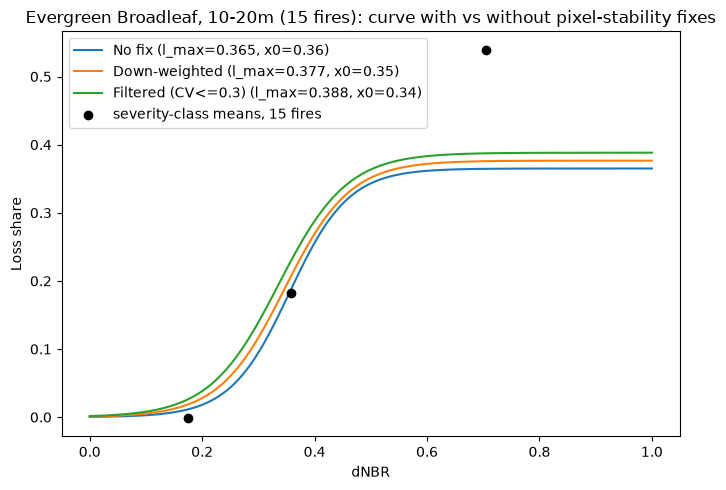

In [29]:
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

def fit_group_weighted(df, weight_col, dnbr_col="dnbr", loss_col="loss2022", min_fires=3, min_cells=200):
    n_fires = df["uid"].nunique()
    if n_fires < min_fires or len(df) < min_cells:
        return {"status": "insufficient_data", "n_fires": n_fires, "n_cells": len(df)}
    x = df[dnbr_col].to_numpy()
    y = df[loss_col].to_numpy()
    sigma = 1 / df[weight_col].to_numpy()  # curve_fit weights points with smaller sigma more
    k_upper_bound, l_max_upper_bound = 50, 1
    try:
        popt, pcov = curve_fit(
            logistic, x, y, sigma=sigma,
            p0=[0.5, 5, 0.4],
            bounds=([0, 0, -1], [l_max_upper_bound, k_upper_bound, 2]),
            maxfev=5000,
        )
    except RuntimeError as e:
        return {"status": "fit_failed", "error": str(e), "n_fires": n_fires, "n_cells": len(df)}
    param_std_err = np.sqrt(np.diag(pcov))
    degenerate = (
        popt[1] >= k_upper_bound * 0.999 or popt[1] <= k_upper_bound * 0.01
        or popt[0] >= l_max_upper_bound * 0.999
        or param_std_err[0] > 1 or param_std_err[1] > k_upper_bound
    )
    return {"status": "degenerate_fit" if degenerate else "fitted",
            "l_max": popt[0], "k": popt[1], "x0": popt[2],
            "n_fires": n_fires, "n_cells": len(df)}

# same 15 fires for all three, so this isolates the effect of the fix, not fire count
eb15 = grp_eb_with_cv.copy()
eb15["weight"] = 1 / (1 + eb15["cv"].clip(lower=0))
eb15_filtered = eb15[eb15["cv"] <= 0.3]

fit_plain = fit_group(eb15, min_fires=3, min_cells=200)
fit_weighted = fit_group_weighted(eb15, weight_col="weight", min_fires=3, min_cells=200)
fit_filtered = fit_group(eb15_filtered, min_fires=3, min_cells=200)

for label, fit in [("No fix", fit_plain), ("Down-weighted", fit_weighted), ("Filtered (CV<=0.3)", fit_filtered)]:
    print(label, fit)

x_grid = np.linspace(0, 1, 100)
plt.figure(figsize=(7, 5))
for label, fit in [("No fix", fit_plain), ("Down-weighted", fit_weighted), ("Filtered (CV<=0.3)", fit_filtered)]:
    if fit["status"] in ("fitted", "degenerate_fit"):
        plt.plot(x_grid, logistic(x_grid, fit["l_max"], fit["k"], fit["x0"]),
                  label=f"{label} (l_max={fit['l_max']:.3f}, x0={fit['x0']:.2f})")

means = eb15.groupby("severity", observed=True).agg(dnbr=("dnbr", "mean"), loss=("loss2022", "mean")).reset_index()
plt.scatter(means["dnbr"], means["loss"], color="black", zorder=5, label="severity-class means, 15 fires")

plt.xlabel("dNBR")
plt.ylabel("Loss share")
plt.title("Evergreen Broadleaf, 10-20m (15 fires): curve with vs without pixel-stability fixes")
plt.legend()
plt.tight_layout()
plt.savefig("../data/processed/eb_stability_refit_comparison.png", dpi=150)
plt.show()
